# Walking vs Running Classification from Wrist-Worn Motion Sensors
**Project PRCP-1013 – Walk/Run Classification**

This single notebook covers every deliverable in the problem statement:

| # | Deliverable | Section |
|---|-------------|---------|
| 1 | Complete data analysis report | Part 1 |
| 2 | Predictive model: walking vs running | Part 2 |
| 3 | Model comparison report + production recommendation | Part 3 |
| 4 | Report on challenges faced and techniques used | Part 4 |

**Dataset:** 88,588 readings from a wrist-worn accelerometer + gyroscope (≈5 readings per second).
`activity` is the target (0 = walking, 1 = running). Predictors are `acceleration_x/y/z`, `gyro_x/y/z` and `wrist`
(0 = left, 1 = right). `date`, `time` and `username` are metadata.

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import GroupKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Locate the data file (works whether you run next to the unzipped 'Data' folder or not)
CANDIDATES = ["Data/walkrun.csv", "walkrun.csv", "data/walkrun.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
print("Using data file:", DATA_PATH)

Using data file: Data/walkrun.csv


# PART 1 — Data Analysis Report (Task 1)
## 1.1 Load the data and first look

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (88588, 11)


,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,2017-6-30,13:51:15:847724020,viktor,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,2017-6-30,13:51:16:246945023,viktor,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,2017-6-30,13:51:16:446233987,viktor,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,2017-6-30,13:51:16:646117985,viktor,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,2017-6-30,13:51:16:846738994,viktor,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            88588 non-null  str    
 1   time            88588 non-null  str    
 2   username        88588 non-null  str    
 3   wrist           88588 non-null  int64  
 4   activity        88588 non-null  int64  
 5   acceleration_x  88588 non-null  float64
 6   acceleration_y  88588 non-null  float64
 7   acceleration_z  88588 non-null  float64
 8   gyro_x          88588 non-null  float64
 9   gyro_y          88588 non-null  float64
 10  gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 7.4 MB


### 1.2 Data quality checks
Missing values, duplicates, cardinality of categorical columns and constant columns.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
})
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate (date,time):", df.duplicated(subset=["date", "time"]).sum())
print("Usernames            :", df["username"].unique())
quality

Duplicate rows       : 0
Duplicate (date,time): 0
Usernames            : <StringArray>
['viktor']
Length: 1, dtype: str


,dtype,missing,n_unique
date,str,0,12
time,str,0,88588
username,str,0,1
wrist,int64,0,2
activity,int64,0,2
acceleration_x,float64,0,30307
acceleration_y,float64,0,23957
acceleration_z,float64,0,19698
gyro_x,float64,0,40988
gyro_y,float64,0,38957


In [5]:
SENSORS = ["acceleration_x", "acceleration_y", "acceleration_z", "gyro_x", "gyro_y", "gyro_z"]
df["activity_name"] = df["activity"].map({0: "walking", 1: "running"})
df["wrist_name"] = df["wrist"].map({0: "left", 1: "right"})
df[SENSORS].describe().T.assign(skew=df[SENSORS].skew(), kurtosis=df[SENSORS].kurt())

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
acceleration_x,88588.0,-0.074811,1.009299,-5.3505,-0.381800,-0.0595,0.355500,5.6033,-0.620993,3.420518
acceleration_y,88588.0,-0.562585,0.658458,-3.2990,-1.033500,-0.7591,-0.241775,2.6680,0.907747,0.017944
acceleration_z,88588.0,-0.313956,0.486815,-3.7538,-0.376000,-0.2210,-0.085900,1.6403,-1.837774,4.609747
gyro_x,88588.0,0.004160,1.253423,-4.4306,-0.920700,0.0187,0.888800,4.8742,0.069082,-0.271798
gyro_y,88588.0,0.037203,1.198725,-7.4647,-0.644825,0.0393,0.733700,8.4980,-0.023932,1.489548
gyro_z,88588.0,0.022327,1.914423,-9.4800,-1.345125,0.0069,1.398200,11.2662,0.041732,-0.373312


### 1.3 Time structure and sampling rate
`date` and `time` are strings (`H:MM:SS:nanoseconds`, where the nanosecond field has lost its leading zeros). We combine them into a proper timestamp so that we can
(a) check the sampling rate, (b) rebuild the continuous recording *sessions*, which matters a lot for modelling.

In [6]:
# The last field is the fractional second with its leading zeros stripped (e.g. "46806991" means 0.046806991 s),
# so it must be left-padded to 9 digits before conversion.
t = df["time"].str.split(":", expand=True)
df["timestamp"] = (pd.to_datetime(df["date"], format="%Y-%m-%d")
                   + pd.to_timedelta(t[0].astype(int), unit="h") + pd.to_timedelta(t[1].astype(int), unit="m")
                   + pd.to_timedelta(t[2].astype(int), unit="s") + pd.to_timedelta(t[3].str.zfill(9).astype("int64"), unit="ns"))
print("Already time-ordered?", df["timestamp"].is_monotonic_increasing)
df = df.sort_values("timestamp").reset_index(drop=True)

gap = df["timestamp"].diff().dt.total_seconds()
print(f"Median gap between readings: {gap.median():.3f} s  (~{1/gap.median():.1f} Hz)")
print(f"Readings with a gap > 1 s (recording breaks): {(gap > 1).sum()}")
gap[gap <= 1].describe()

Already time-ordered? False
Median gap between readings: 0.200 s  (~5.0 Hz)
Readings with a gap > 1 s (recording breaks): 338


count    88249.000000
mean         0.203316
std          0.025745
min          0.089312
25%          0.199833
50%          0.200001
75%          0.200190
max          0.999996

In [7]:
# A "session" = an unbroken recording of one (date, wrist, activity) combination
key = df[["date", "wrist", "activity"]]
key_change = (key != key.shift()).any(axis=1)
df["session"] = ((gap > 1.0) | key_change).cumsum()

sessions = (df.groupby("session")
              .agg(date=("date", "first"), wrist=("wrist_name", "first"), activity=("activity_name", "first"),
                   rows=("session", "size"), start=("timestamp", "min"), end=("timestamp", "max")))
sessions["minutes"] = ((sessions["end"] - sessions["start"]).dt.total_seconds() / 60).round(1)
print("Number of sessions:", len(sessions))
print("Rows per session  :", sessions["rows"].describe()[["min", "50%", "max"]].to_dict())
sessions.groupby(["date", "wrist", "activity"]).agg(sessions=("rows", "size"), rows=("rows", "sum"), median_rows=("rows", "median"))

Number of sessions: 339
Rows per session  : {'min': 1.0, '50%': 54.0, 'max': 5681.0}


sessions   rows  median_rows
date      wrist activity                              
2017-6-30 left  running         51   2751         54.0
                walking         23   1241         54.0
2017-7-1  left  running         23   1235         54.0
                walking         55   2966         54.0
2017-7-10 right walking          6   4337        512.5
2017-7-11 right running          3   6696       1248.0
2017-7-15 right running          4   7150        661.0
                walking          1    784        784.0
2017-7-16 right walking         13  20480       1519.0
2017-7-17 left  walking          4   4554       1052.0
          right running          2   6811       3405.5
2017-7-2  left  running         66   3504         54.0
                walking          8    429         54.0
2017-7-4  left  running         57   2901         54.0
                walking          6    324         54.0
2017-7-6  left  running          6   6411       1104.5
                walking          5   4946       1222.0
2017-7-7  left  walking          2   3280       1640.0
2017-7-9  left  running          3   6906        784.0
                walking          1    882        882.0

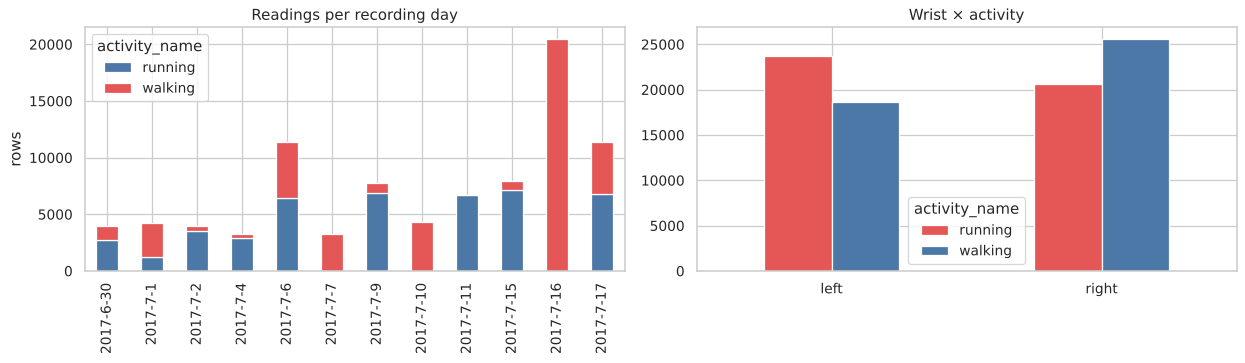

activity_name,running,walking
date,,
2017-6-30,2751,1241
2017-7-1,1235,2966
2017-7-2,3504,429
2017-7-4,2901,324
2017-7-6,6411,4946
2017-7-7,0,3280
2017-7-9,6906,882
2017-7-10,0,4337
2017-7-11,6696,0


In [8]:
by_day = df.groupby(["date", "activity_name"]).size().unstack(fill_value=0)
by_day = by_day.loc[sorted(by_day.index, key=lambda s: pd.to_datetime(s))]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
by_day.plot(kind="bar", stacked=True, ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Readings per recording day"); ax[0].set_ylabel("rows"); ax[0].set_xlabel("")
pd.crosstab(df["wrist_name"], df["activity_name"]).plot(kind="bar", ax=ax[1], color=["#E45756", "#4C78A8"], rot=0)
ax[1].set_title("Wrist × activity"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
by_day

### 1.4 Target distribution

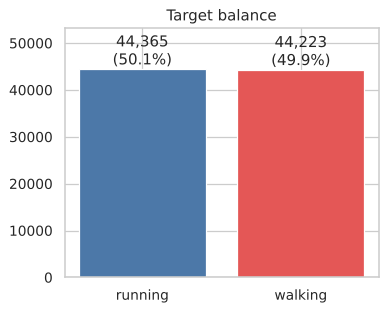

In [9]:
counts = df["activity_name"].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3.6))
ax.bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2); ax.set_title("Target balance")
plt.show()

### 1.5 Feature distributions by activity

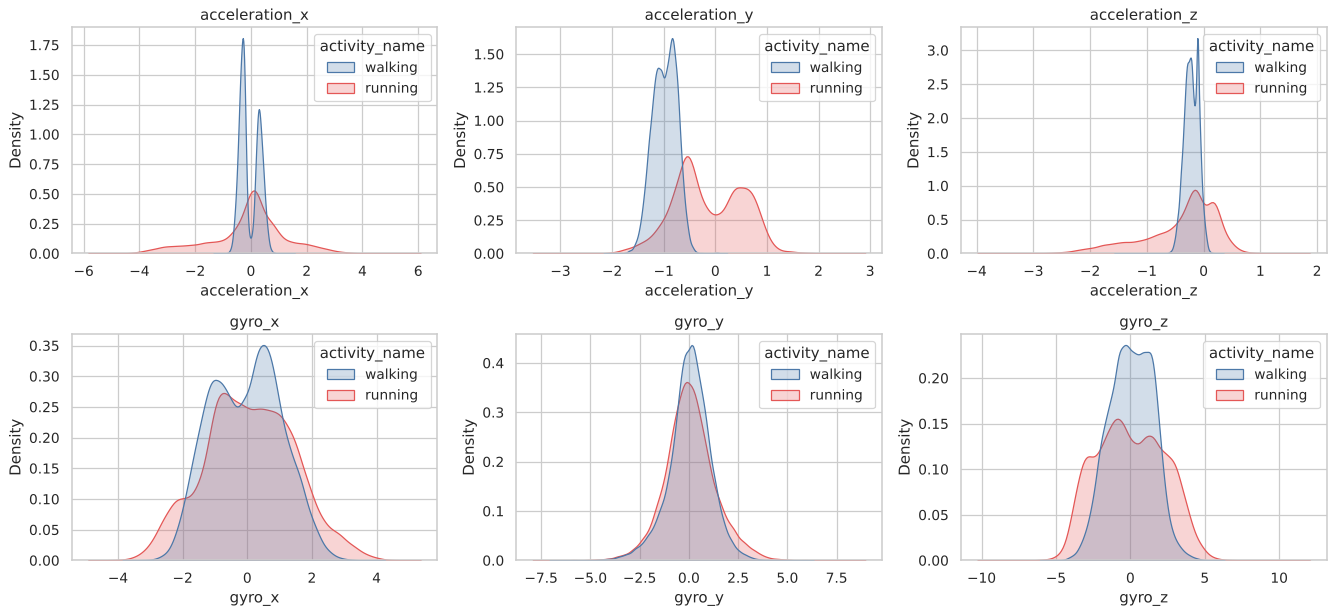

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), SENSORS):
    sns.kdeplot(data=df, x=col, hue="activity_name", fill=True, common_norm=False,
                palette={"walking": "#4C78A8", "running": "#E45756"}, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

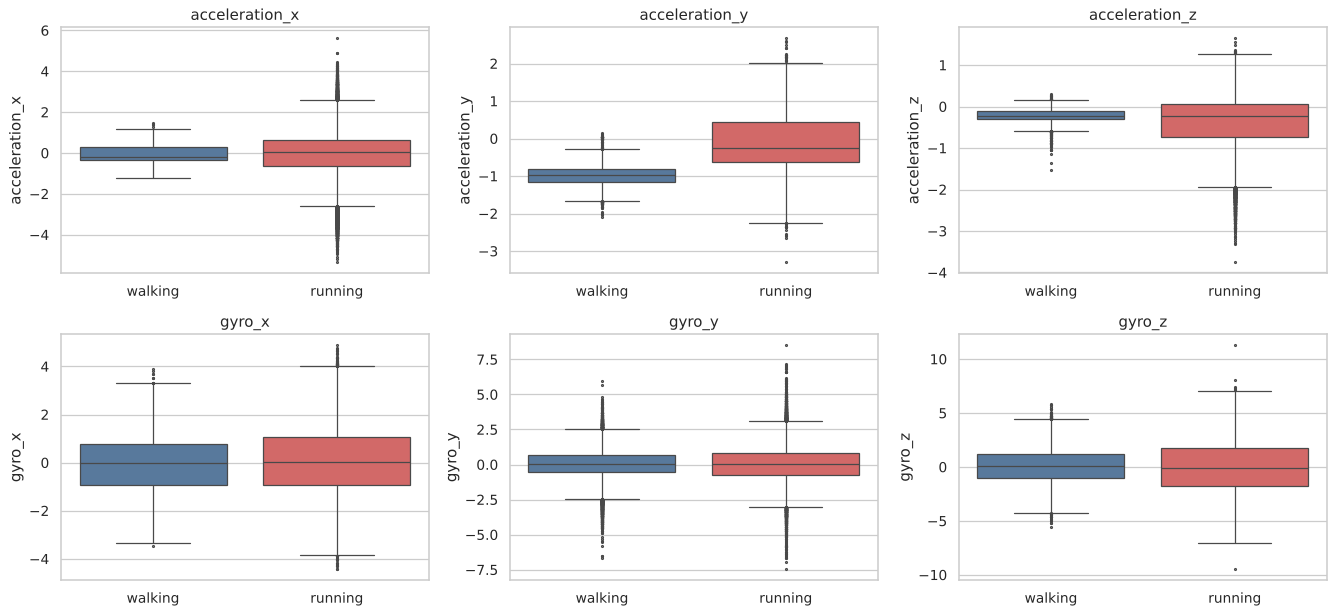

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), SENSORS):
    sns.boxplot(data=df, x="activity_name", y=col, hue="activity_name", ax=ax, legend=False,
                palette={"walking": "#4C78A8", "running": "#E45756"}, fliersize=1.5)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 1.6 Statistical test: does each sensor differ between walking and running?
Features are skewed, so we use the non-parametric Mann–Whitney U test and report a rank-biserial effect size
(0 = no separation, 1 = perfect separation). With ~88k rows every p-value will be tiny, so the **effect size** is the useful number.

In [12]:
rows = []
for col in SENSORS:
    a = df.loc[df.activity == 0, col]; b = df.loc[df.activity == 1, col]
    u, p = stats.mannwhitneyu(a, b)
    effect = abs(2 * u / (len(a) * len(b)) - 1)
    rows.append({"feature": col, "mean_walk": a.mean(), "mean_run": b.mean(),
                 "std_walk": a.std(), "std_run": b.std(), "p_value": p, "effect_size": effect})
pd.DataFrame(rows).set_index("feature").round(4).sort_values("effect_size", ascending=False)

,mean_walk,mean_run,std_walk,std_run,p_value,effect_size
feature,,,,,,
acceleration_y,-0.9844,-0.1422,0.2317,0.6769,0.0000,0.7745
acceleration_x,-0.0569,-0.0927,0.3504,1.3824,0.0000,0.0858
gyro_x,-0.0471,0.0553,1.0873,1.3977,0.0000,0.0465
acceleration_z,-0.2201,-0.4075,0.1257,0.6633,0.0000,0.0328
gyro_z,0.0379,0.0068,1.4648,2.2758,0.0000,0.0167
gyro_y,0.0227,0.0516,1.0761,1.3095,0.0006,0.0133


### 1.7 Orientation vs. intensity: acceleration/gyro magnitude and the raw signal
`acceleration_y` mostly tracks how the wrist is oriented with gravity; *magnitude* features are orientation-independent.

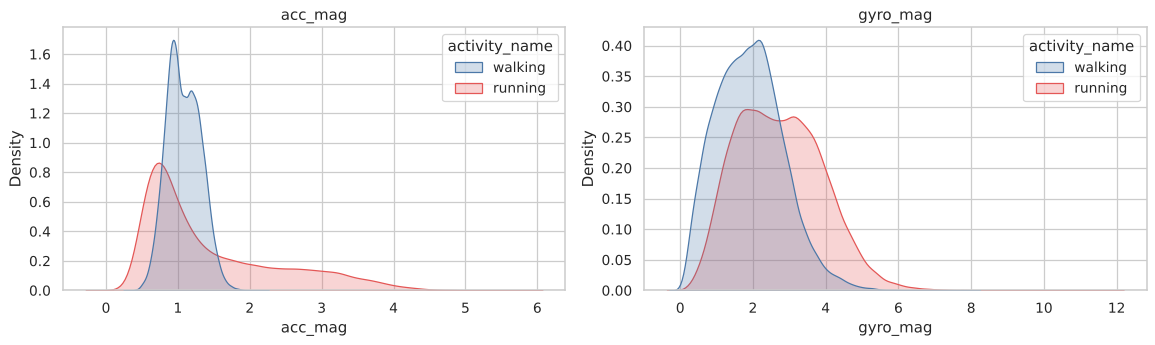

In [13]:
df["acc_mag"] = np.sqrt((df[["acceleration_x", "acceleration_y", "acceleration_z"]] ** 2).sum(axis=1))
df["gyro_mag"] = np.sqrt((df[["gyro_x", "gyro_y", "gyro_z"]] ** 2).sum(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["acc_mag", "gyro_mag"]):
    sns.kdeplot(data=df, x=col, hue="activity_name", fill=True, common_norm=False,
                palette={"walking": "#4C78A8", "running": "#E45756"}, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

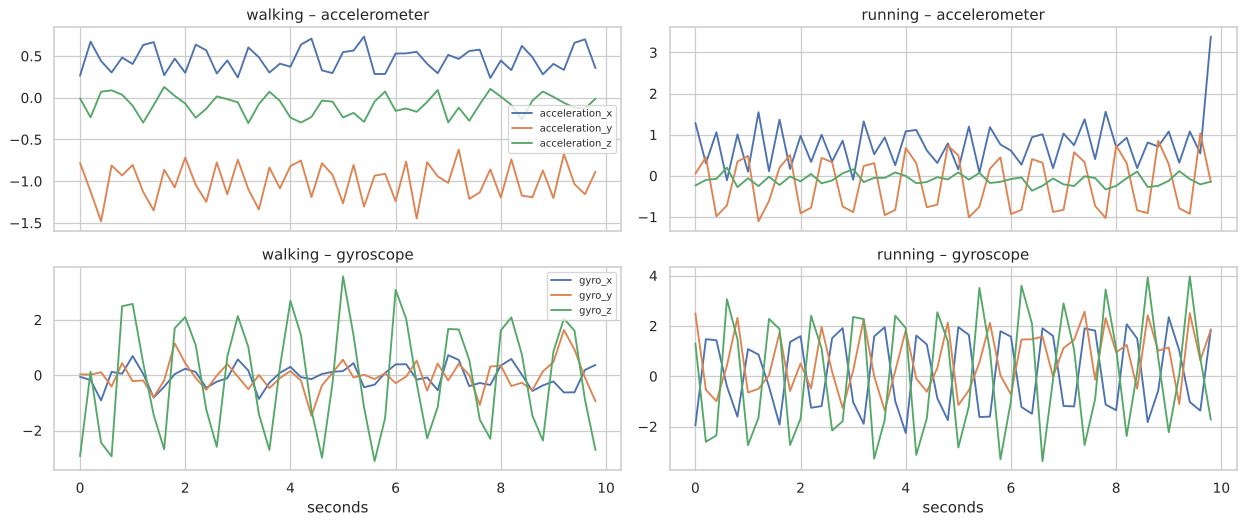

In [14]:
# 10-second raw-signal snippet (50 readings) from one walking and one running session
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True)
for j, act in enumerate(["walking", "running"]):
    sid = sessions[(sessions.activity == act) & (sessions.rows >= 50)].index[0]
    seg = df[df.session == sid].iloc[:50]
    t = np.arange(len(seg)) * 0.2
    for c in SENSORS[:3]: axes[0, j].plot(t, seg[c].values, label=c)
    for c in SENSORS[3:]: axes[1, j].plot(t, seg[c].values, label=c)
    axes[0, j].set_title(f"{act} – accelerometer"); axes[1, j].set_title(f"{act} – gyroscope")
    axes[1, j].set_xlabel("seconds")
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1.8 Correlation analysis

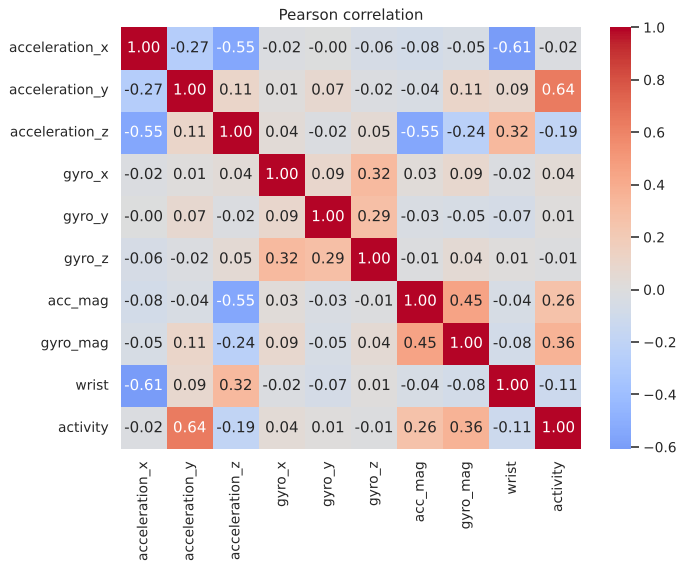

In [15]:
num_cols = SENSORS + ["acc_mag", "gyro_mag", "wrist", "activity"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlation")
plt.tight_layout(); plt.show()

### 1.9 Outliers

In [16]:
def iqr_outlier_pct(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100

out = df.groupby("activity_name")[SENSORS].agg(iqr_outlier_pct).T.round(2)
out.columns = [f"% outliers ({c})" for c in out.columns]
out

,% outliers (running),% outliers (walking)
acceleration_x,9.26,0.01
acceleration_y,0.09,0.25
acceleration_z,3.33,0.24
gyro_x,0.16,0.02
gyro_y,3.09,3.32
gyro_z,0.02,0.13


### 1.10 Does the wrist matter?

In [17]:
df.groupby(["wrist_name", "activity_name"])[SENSORS].mean().round(3)

acceleration_x  acceleration_y  acceleration_z  gyro_x  gyro_y  gyro_z
wrist_name activity_name                                                                        
left       running                 0.763          -0.327          -0.699   0.112   0.211  -0.037
           walking                 0.321          -0.999          -0.198  -0.067   0.010   0.058
right      running                -1.074           0.070          -0.073  -0.009  -0.132   0.057
           walking                -0.332          -0.974          -0.236  -0.033   0.032   0.023

## 1.11 Summary of findings from the data analysis

| Topic | Finding |
|---|---|
| Size / quality | 88,588 rows × 11 columns. **No missing values, no duplicate rows, no duplicate timestamps.** |
| Constant column | `username` has a single value (`viktor`) → no information; dropped. This is a **single-person dataset**. |
| Target | Almost perfectly balanced overall (walking 44,223 / running 44,365), so accuracy is a fair metric overall. Balance is **not** uniform per day (see 2.1). |
| Sampling | Median gap 0.200 s ⇒ **5 Hz**. 338 breaks (>1 s) split the data into **339 recording sessions**: many short ~54-row (≈11 s) chunks on early days, long continuous recordings (up to 5,681 rows) on later days. |
| Structure | Days are not interchangeable: 7/16 has only walking, 7/10 only walking, 7/11 only running. Wrist and activity are also entangled with the day. |
| Strongest signal | `acceleration_y` (rank-biserial effect size 0.77; mean −0.98 walking vs −0.14 running). All other single channels have effect sizes below 0.09 on their own. |
| Spread, not centre | Running has far larger variance than walking on every accelerometer axis (e.g. `acceleration_x` std 1.38 vs 0.35; `acceleration_z` 0.66 vs 0.13) — running is a more violent, higher-amplitude motion. |
| Wrist | The signs of the means flip between left and right wrist (e.g. running `acceleration_x` +0.76 left vs −1.07 right) because the sensor is mirrored. Wrist is therefore a useful context feature. |
| Distributions | Skewed / heavy-tailed (e.g. `acceleration_z` skew ≈ −1.8). |
| Outliers | By IQR rule 9.3% of running `acceleration_x` and 3.3% of running `acceleration_z` readings are "outliers", versus ~0% for walking. These are **genuine high-impact foot strikes, not errors**, so they are kept. |
| Correlation | Raw channels are weakly correlated with each other; `acceleration_y` is the only one strongly correlated with the target. |

**Implication for modelling:** one reading is a noisy snapshot of a periodic motion, and the information that separates the classes is largely in the *amplitude/variability over time*. That motivates window-level features (Part 2.4) and day-grouped validation.

# PART 2 — Predictive Modelling (Task 2)

## 2.1 Modelling strategy (decisions made *before* fitting anything)

1. **Drop `username`** – only one user (`viktor`), a constant column carries no information.
2. **Drop `date` / `time` as predictors** – they would let a model memorise *when* an activity was recorded
   (e.g. "7/16 → walking"), which will not generalise to new recordings. They are used only to rebuild sessions
   and as **group identifiers** for validation.
3. **Validation must be grouped by recording day.** Readings arrive 5 times a second, so neighbouring rows are almost identical.
   A random train/test split puts near-copies of the same moment on both sides and inflates scores.
   We prove this below and use `GroupKFold` (by `date`) for all model selection.
4. **A final hold-out set of whole days** is locked away and touched only once at the end.
5. Two feature views are compared: **row-level** (single reading) and **window-level** (statistics over 5 seconds of readings),
   since a single instantaneous reading of a periodic motion is a very noisy snapshot.

In [18]:
# --- hold-out: two full days that contain BOTH activities and both wrists' conditions ---
TEST_DATES = ["2017-7-15", "2017-7-17"]
test_mask = df["date"].isin(TEST_DATES)
train_df, test_df = df[~test_mask].copy(), df[test_mask].copy()

print(f"Train rows: {len(train_df):,} ({train_df.date.nunique()} days) | Test rows: {len(test_df):,} ({test_df.date.nunique()} days)")
print("Train class share:", train_df.activity.value_counts(normalize=True).round(3).to_dict())
print("Test  class share:", test_df.activity.value_counts(normalize=True).round(3).to_dict())

ROW_FEATS = SENSORS + ["acc_mag", "gyro_mag", "wrist"]
X_row, y_row, g_row = train_df[ROW_FEATS], train_df["activity"], train_df["date"]

Train rows: 69,289 (10 days) | Test rows: 19,299 (2 days)
Train class share: {0: 0.561, 1: 0.439}
Test  class share: {1: 0.723, 0: 0.277}


## 2.2 Why a random split is misleading (data-leakage demonstration)
Same model, same data – only the validation scheme differs.

In [19]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)

def cv_acc(splitter, **kw):
    accs = []
    for tr, va in splitter.split(X_row, y_row, **kw):
        accs.append(accuracy_score(y_row.iloc[va], clone(rf).fit(X_row.iloc[tr], y_row.iloc[tr]).predict(X_row.iloc[va])))
    return np.array(accs)

rand = cv_acc(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
grp = cv_acc(GroupKFold(5), groups=g_row)
print(f"Random shuffled 5-fold : accuracy = {rand.mean():.4f} ± {rand.std():.4f}")
print(f"Grouped-by-day 5-fold  : accuracy = {grp.mean():.4f} ± {grp.std():.4f}")
print("-> the random split over-estimates accuracy; we use grouped CV from here on.")

Random shuffled 5-fold : accuracy = 0.9919 ± 0.0008
Grouped-by-day 5-fold  : accuracy = 0.8860 ± 0.1906
-> the random split over-estimates accuracy; we use grouped CV from here on.


## 2.3 Model comparison on single readings (row-level features)
Eleven model families covering linear, probabilistic, distance-based, tree, ensemble, kernel and neural approaches.
Scale-sensitive models are wrapped in a `StandardScaler` pipeline. The RBF-SVM is trained on a 12k random subsample per fold
(an exact SVM on 70k rows is O(n²–n³)); this is noted in the results.

In [20]:
class SubsampleSVC(BaseEstimator, ClassifierMixin):
    """Scaler + RBF-SVM fitted on at most `max_samples` rows (keeps training time practical)."""
    def __init__(self, max_samples=12000, C=1.0, gamma="scale", random_state=42):
        self.max_samples, self.C, self.gamma, self.random_state = max_samples, C, gamma, random_state
    def fit(self, X, y):
        X = np.asarray(X); y = np.asarray(y)
        idx = np.random.RandomState(self.random_state).permutation(len(X))[: self.max_samples]
        self.scaler_ = StandardScaler().fit(X[idx])
        self.svc_ = SVC(C=self.C, gamma=self.gamma).fit(self.scaler_.transform(X[idx]), y[idx])
        self.classes_ = self.svc_.classes_
        return self
    def predict(self, X): return self.svc_.predict(self.scaler_.transform(np.asarray(X)))
    def decision_function(self, X): return self.svc_.decision_function(self.scaler_.transform(np.asarray(X)))

def get_models(svm_samples=12000):
    return {
        "Dummy (majority)":      DummyClassifier(strategy="most_frequent"),
        "Logistic Regression":   make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "Gaussian Naive Bayes":  GaussianNB(),
        "KNN (k=15)":            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
        "Decision Tree":         DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
        "Random Forest":         RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
        "Extra Trees":           ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
        "Hist. Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        "AdaBoost":              AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "SVM (RBF)":             SubsampleSVC(max_samples=svm_samples),
        "MLP (64-32)":           make_pipeline(StandardScaler(), MLPClassifier((64, 32), early_stopping=True, max_iter=100, random_state=RANDOM_STATE)),
    }

def get_score(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def evaluate(models, X, y, groups, n_splits=5):
    """Grouped CV. Returns summary table and out-of-fold predictions."""
    rows, oof = [], {}
    for name, est in models.items():
        t0 = time.time()
        pred = np.zeros(len(y), int); score = np.zeros(len(y)); accs, f1s = [], []
        for tr, va in GroupKFold(n_splits).split(X, y, groups):
            m = clone(est).fit(X.iloc[tr], y.iloc[tr])
            p = m.predict(X.iloc[va]); pred[va] = p; score[va] = get_score(m, X.iloc[va])
            accs.append(accuracy_score(y.iloc[va], p)); f1s.append(f1_score(y.iloc[va], p, average="macro"))
        yy = y.to_numpy()
        rows.append({"model": name,
                     "cv_accuracy": np.mean(accs), "acc_std": np.std(accs), "cv_f1_macro": np.mean(f1s),
                     "precision": precision_score(yy, pred, zero_division=0), "recall": recall_score(yy, pred),
                     "roc_auc": roc_auc_score(yy, score) if len(np.unique(score)) > 1 else 0.5,
                     "fit_time_s": time.time() - t0})
        oof[name] = (pred, score)
        print(f"  {name:<26} acc={np.mean(accs):.4f} ± {np.std(accs):.4f}   ({time.time()-t0:.0f}s)")
    return pd.DataFrame(rows).set_index("model"), oof

for i, (tr, va) in enumerate(GroupKFold(5).split(X_row, y_row, g_row)):
    print(f"fold {i}: days={sorted(g_row.iloc[va].unique())}  walking={int((y_row.iloc[va]==0).sum())}  running={int((y_row.iloc[va]==1).sum())}")

fold 0: days=['2017-7-16']  walking=20480  running=0
fold 1: days=['2017-7-6']  walking=4946  running=6411
fold 2: days=['2017-7-2', '2017-7-9']  walking=1311  running=10410
fold 3: days=['2017-6-30', '2017-7-11', '2017-7-4']  walking=1565  running=12348
fold 4: days=['2017-7-1', '2017-7-10', '2017-7-7']  walking=10583  running=1235


In [21]:
print("Row-level feature set – grouped 5-fold CV")
res_row, oof_row = evaluate(get_models(), X_row, y_row, g_row)
res_row.round(4).sort_values("cv_accuracy", ascending=False)

Row-level feature set – grouped 5-fold CV
  Dummy (majority)           acc=0.1529 ± 0.1476   (0s)
  Logistic Regression        acc=0.9206 ± 0.0432   (0s)
  Gaussian Naive Bayes       acc=0.8362 ± 0.2157   (0s)
  KNN (k=15)                 acc=0.9157 ± 0.1454   (9s)
  Decision Tree              acc=0.8720 ± 0.1903   (2s)
  Random Forest              acc=0.8861 ± 0.1907   (133s)
  Extra Trees                acc=0.8913 ± 0.1923   (22s)
  Hist. Gradient Boosting    acc=0.8892 ± 0.1936   (4s)
  AdaBoost                   acc=0.8982 ± 0.1294   (63s)
  SVM (RBF)                  acc=0.9495 ± 0.0737   (5s)
  MLP (64-32)                acc=0.8930 ± 0.1886   (24s)


,cv_accuracy,acc_std,cv_f1_macro,precision,recall,roc_auc,fit_time_s
model,,,,,,,
SVM (RBF),0.9495,0.0737,0.8197,0.9820,0.9024,0.9709,4.9057
Logistic Regression,0.9206,0.0432,0.7783,0.9303,0.8861,0.9300,0.4647
KNN (k=15),0.9157,0.1454,0.7921,0.9879,0.8198,0.9339,8.6834
AdaBoost,0.8982,0.1294,0.7697,0.9470,0.8106,0.9277,63.4842
MLP (64-32),0.8930,0.1886,0.7779,0.9722,0.7765,0.8458,23.9536
Extra Trees,0.8913,0.1923,0.7749,0.9769,0.7702,0.9446,21.7317
Hist. Gradient Boosting,0.8892,0.1936,0.7744,0.9679,0.7708,0.7787,4.3817
Random Forest,0.8861,0.1907,0.7716,0.9577,0.7700,0.9665,132.6967
Decision Tree,0.8720,0.1903,0.7497,0.9527,0.7445,0.7607,2.1003


**Reading the row-level table.** On single readings, nothing is better than ~95% (RBF-SVM) and the tree ensembles sit near 89%.
The large `acc_std` values arise because validation folds are whole days, and some days are very different from the training days
(and some folds contain a single class), so a model that merely "memorised" the training days fails on them. The majority-class
dummy scores *below* 50% for the same reason – the majority class in training is the minority in some validation folds.
Pooled ROC-AUC is computed from out-of-fold scores of different fold models, so it is a rough guide rather than an exact figure.

## 2.4 Window-level features (5-second windows)
Walking and running differ mainly in **cadence and intensity of repeated arm swing**. A single 0.2 s reading catches the arm at an
arbitrary phase of the swing, whereas a window of 25 consecutive readings (≈5 s) lets us summarise the signal with mean, spread,
extremes and quartiles of every channel – a standard approach in human-activity recognition.

* Windows are built **inside a session only** (never across a recording break or an activity change).
* Window = 25 readings, stride = 10 (60% overlap) to create more training examples. Overlap is harmless for validation because
  grouping is by *day*, so overlapping windows never straddle train/validation.
* The same function will be used in production on any 25 consecutive readings.

In [22]:
CHANNELS = SENSORS + ["acc_mag", "gyro_mag"]
STATS = ["mean", "std", "min", "max", "median", "q25", "q75"]
WINDOW, STRIDE = 25, 10

def window_stats(arr):
    """arr: (n_windows, n_channels, window) -> (n_windows, n_channels*len(STATS)) feature matrix."""
    q25, q75 = np.percentile(arr, [25, 75], axis=2)
    parts = [arr.mean(2), arr.std(2), arr.min(2), arr.max(2), np.median(arr, 2), q25, q75]
    return np.stack(parts, axis=2).reshape(arr.shape[0], -1)     # ordered channel-major, stat-minor

WIN_FEATS = [f"{c}_{s}" for c in CHANNELS for s in STATS] + ["wrist"]

def make_windows(d, win=WINDOW, step=STRIDE):
    X, y, g = [], [], []
    for sid, s in d.groupby("session"):
        if len(s) < win: continue
        view = sliding_window_view(s[CHANNELS].to_numpy(), win, axis=0)[::step]   # (nw, ch, win)
        f = window_stats(view)
        X.append(np.column_stack([f, np.full(len(f), s["wrist"].iloc[0])]))
        y.append(np.full(len(f), s["activity"].iloc[0])); g.append(np.full(len(f), s["date"].iloc[0]))
    return (pd.DataFrame(np.vstack(X), columns=WIN_FEATS),
            pd.Series(np.concatenate(y), name="activity"), pd.Series(np.concatenate(g), name="date"))

Xw, yw, gw = make_windows(train_df)
Xw_test, yw_test, gw_test = make_windows(test_df)
print("Train windows:", Xw.shape, "| class share:", yw.value_counts(normalize=True).round(3).to_dict())
print("Test  windows:", Xw_test.shape, "| class share:", yw_test.value_counts(normalize=True).round(3).to_dict())
Xw.iloc[:, :8].head()

Train windows: (6172, 57) | class share: {0: 0.586, 1: 0.414}
Test  windows: (1908, 57) | class share: {1: 0.725, 0: 0.275}


,acceleration_x_mean,acceleration_x_std,acceleration_x_min,acceleration_x_max,acceleration_x_median,acceleration_x_q25,acceleration_x_q75,acceleration_y_mean
0,0.449088,0.149159,0.2424,0.7090,0.4399,0.3017,0.6028,-0.994596
1,0.453976,0.147222,0.2424,0.7335,0.4477,0.2985,0.5656,-0.995916
2,0.463392,0.141590,0.2365,0.7335,0.4872,0.3275,0.5604,-0.994884
3,0.454024,0.139924,0.2491,0.6929,0.4545,0.3197,0.5738,-1.005464
4,0.442492,0.133056,0.2549,0.6122,0.4465,0.3073,0.5844,-1.013928


In [23]:
print("Window-level feature set – grouped 5-fold CV")
res_win, oof_win = evaluate(get_models(svm_samples=20000), Xw, yw, gw)
res_win.round(4).sort_values("cv_accuracy", ascending=False)

Window-level feature set – grouped 5-fold CV
  Dummy (majority)           acc=0.3116 ± 0.3013   (0s)
  Logistic Regression        acc=0.9994 ± 0.0011   (0s)
  Gaussian Naive Bayes       acc=0.8735 ± 0.2447   (0s)
  KNN (k=15)                 acc=0.9412 ± 0.1176   (0s)
  Decision Tree              acc=1.0000 ± 0.0000   (0s)
  Random Forest              acc=0.9985 ± 0.0022   (6s)
  Extra Trees                acc=0.9962 ± 0.0065   (2s)
  Hist. Gradient Boosting    acc=0.9990 ± 0.0012   (2s)
  AdaBoost                   acc=0.9996 ± 0.0008   (0s)
  SVM (RBF)                  acc=0.9998 ± 0.0004   (0s)
  MLP (64-32)                acc=0.9282 ± 0.1293   (1s)


,cv_accuracy,acc_std,cv_f1_macro,precision,recall,roc_auc,fit_time_s
model,,,,,,,
Decision Tree,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.1839
SVM (RBF),0.9998,0.0004,0.9996,0.9996,1.0000,0.9999,0.4359
AdaBoost,0.9996,0.0008,0.9992,0.9992,1.0000,0.9997,0.1987
Logistic Regression,0.9994,0.0011,0.9990,1.0000,0.9988,1.0000,0.0990
Hist. Gradient Boosting,0.9990,0.0012,0.9982,0.9992,0.9988,0.9999,2.4474
Random Forest,0.9985,0.0022,0.9973,0.9992,0.9977,0.9999,5.8866
Extra Trees,0.9962,0.0065,0.9935,0.9992,0.9930,0.9999,1.9439
KNN (k=15),0.9412,0.1176,0.9321,1.0000,0.8760,0.9945,0.4081
MLP (64-32),0.9282,0.1293,0.8245,0.9735,0.8611,0.9846,0.9649


# PART 3 — Model Comparison Report (Task 3)
## 3.1 Side-by-side results (grouped-by-day cross-validation)

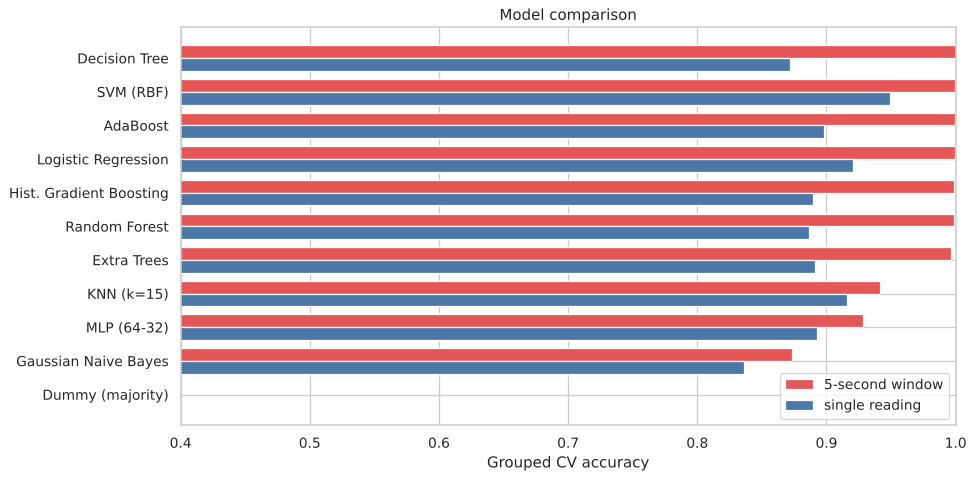

,Acc (row),F1 (row),AUC (row),Acc (window),F1 (window),AUC (window),Acc std (window)
model,,,,,,,
Decision Tree,0.8720,0.7497,0.7607,1.0000,1.0000,1.0000,0.0000
SVM (RBF),0.9495,0.8197,0.9709,0.9998,0.9996,0.9999,0.0004
AdaBoost,0.8982,0.7697,0.9277,0.9996,0.9992,0.9997,0.0008
Logistic Regression,0.9206,0.7783,0.9300,0.9994,0.9990,1.0000,0.0011
Hist. Gradient Boosting,0.8892,0.7744,0.7787,0.9990,0.9982,0.9999,0.0012
Random Forest,0.8861,0.7716,0.9665,0.9985,0.9973,0.9999,0.0022
Extra Trees,0.8913,0.7749,0.9446,0.9962,0.9935,0.9999,0.0065
KNN (k=15),0.9157,0.7921,0.9339,0.9412,0.9321,0.9945,0.1176
MLP (64-32),0.8930,0.7779,0.8458,0.9282,0.8245,0.9846,0.1293


In [24]:
cmp = pd.concat({"single reading": res_row, "5-s window": res_win}, axis=1)
summary = pd.DataFrame({
    "Acc (row)": res_row["cv_accuracy"], "F1 (row)": res_row["cv_f1_macro"], "AUC (row)": res_row["roc_auc"],
    "Acc (window)": res_win["cv_accuracy"], "F1 (window)": res_win["cv_f1_macro"], "AUC (window)": res_win["roc_auc"],
    "Acc std (window)": res_win["acc_std"],
}).round(4).sort_values("Acc (window)", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
order = summary.index[::-1]
y_pos = np.arange(len(order)); h = 0.38
ax.barh(y_pos + h/2, summary.loc[order, "Acc (window)"], h, label="5-second window", color="#E45756")
ax.barh(y_pos - h/2, summary.loc[order, "Acc (row)"], h, label="single reading", color="#4C78A8")
ax.set_yticks(y_pos); ax.set_yticklabels(order); ax.set_xlim(0.4, 1.0)
ax.set_xlabel("Grouped CV accuracy"); ax.set_title("Model comparison"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
summary

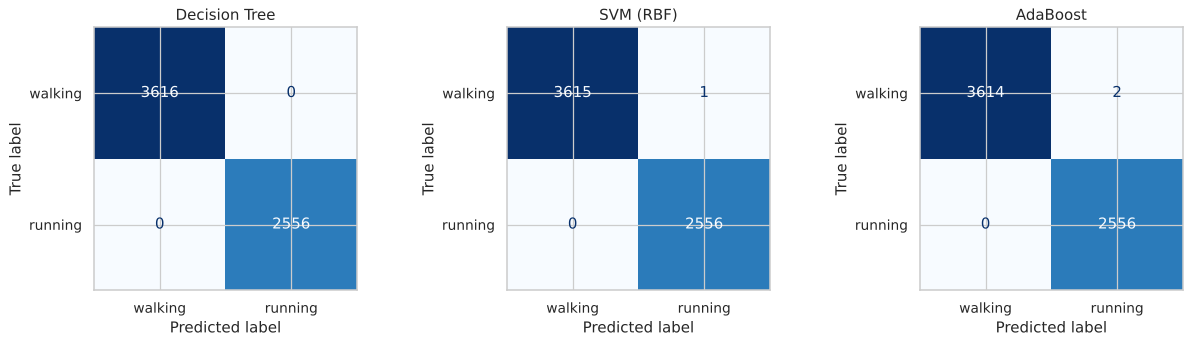

In [25]:
# Confusion matrices of out-of-fold predictions for the top-3 window models
top3 = summary.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, top3):
    ConfusionMatrixDisplay.from_predictions(yw, oof_win[name][0], display_labels=["walking", "running"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

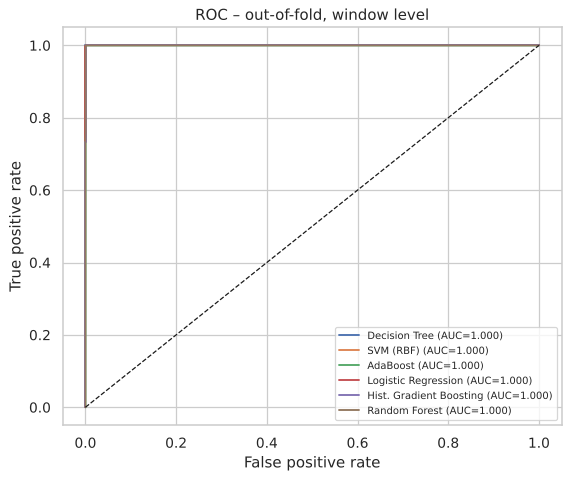

In [26]:
# ROC curves, window level
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in summary.index[:6]:
    fpr, tpr, _ = roc_curve(yw, oof_win[name][1])
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yw, oof_win[name][1]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC – out-of-fold, window level"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3.2 Hyper-parameter tuning of the strongest candidates
Randomised search, scored with the same grouped-by-day CV, on window-level features.

In [27]:
search_space = {
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        {"n_estimators": [200, 400], "max_depth": [None, 8, 12, 20], "min_samples_leaf": [1, 3, 5, 10],
         "max_features": ["sqrt", 0.3, 0.5]}),
    "Hist. Gradient Boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.05, 0.1, 0.2], "max_depth": [None, 3, 5, 8], "max_leaf_nodes": [15, 31, 63],
         "l2_regularization": [0, 0.1, 1.0], "min_samples_leaf": [10, 20, 50]}),
    "Logistic Regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
}
cv_groups = list(GroupKFold(5).split(Xw, yw, gw))
tuned, tune_rows = {}, []
for name, (est, grid) in search_space.items():
    rs = RandomizedSearchCV(est, grid, n_iter=12 if len(grid) > 1 else 5, cv=cv_groups, scoring="accuracy",
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
    rs.fit(Xw, yw)
    tuned[name] = rs.best_estimator_
    tune_rows.append({"model": name, "tuned_cv_accuracy": rs.best_score_,
                      "default_cv_accuracy": res_win.loc[name, "cv_accuracy"], "best_params": rs.best_params_})
    print(f"{name:<26} default={res_win.loc[name, 'cv_accuracy']:.4f} -> tuned={rs.best_score_:.4f}")
pd.DataFrame(tune_rows).set_index("model")

Random Forest              default=0.9985 -> tuned=0.9996
Hist. Gradient Boosting    default=0.9990 -> tuned=0.9996
Logistic Regression        default=0.9994 -> tuned=1.0000


,tuned_cv_accuracy,default_cv_accuracy,best_params
model,,,
Random Forest,0.999587,0.998474,"{'n_estimators': 200, 'min_samples_leaf': 1, '..."
Hist. Gradient Boosting,0.999587,0.999030,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."
Logistic Regression,1.000000,0.999443,{'logisticregression__C': 100}


## 3.3 Final, one-time evaluation on the locked-away hold-out days
Every tuned model and the row-level baseline are scored on days the models never saw during training or tuning.

In [28]:
def metrics(y_true, pred, score):
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, score)}

final_rows = {}
for name, est in tuned.items():
    est.fit(Xw, yw)                                  # refit on all training windows
    pred = est.predict(Xw_test)
    final_rows[f"{name} (window, tuned)"] = metrics(yw_test, pred, get_score(est, Xw_test))

# row-level baseline for comparison (best row model type: Random Forest)
rf_row = clone(get_models()["Random Forest"]).fit(X_row, y_row)
Xr_test, yr_test = test_df[ROW_FEATS], test_df["activity"]
final_rows["Random Forest (single reading)"] = metrics(yr_test, rf_row.predict(Xr_test), get_score(rf_row, Xr_test))
final_df = pd.DataFrame(final_rows).T.round(4).sort_values("accuracy", ascending=False)
final_df

,accuracy,precision,recall,f1,roc_auc
"Random Forest (window, tuned)",1.0000,1.0000,1.0000,1.0000,1.0000
"Hist. Gradient Boosting (window, tuned)",1.0000,1.0000,1.0000,1.0000,1.0000
"Logistic Regression (window, tuned)",1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest (single reading),0.9775,0.9757,0.9937,0.9846,0.9979


In [29]:
best_name = max(tuned, key=lambda n: accuracy_score(yw_test, tuned[n].predict(Xw_test)))
best_name_cv = max(tune_rows, key=lambda r: r["tuned_cv_accuracy"])["model"]
print("Best on hold-out :", best_name)
print("Best in grouped CV:", best_name_cv)

Best on hold-out : Random Forest
Best in grouped CV: Logistic Regression


### 3.4 Robustness checks of the leading model
Per-wrist performance, confusion matrix, per-day accuracy and inference speed – things that matter in production.

Selected model: Logistic Regression

              precision    recall  f1-score   support

     walking     1.0000    1.0000    1.0000       524
     running     1.0000    1.0000    1.0000      1384

    accuracy                         1.0000      1908
   macro avg     1.0000    1.0000    1.0000      1908
weighted avg     1.0000    1.0000    1.0000      1908

Accuracy by wrist / day / activity


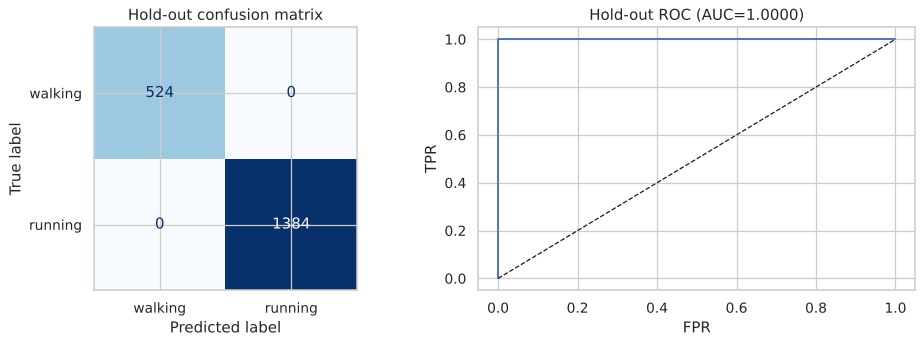

accuracy
wrist    left            1.0
         right           1.0
day      2017-7-15       1.0
         2017-7-17       1.0
activity running         1.0
         walking         1.0

In [30]:
final_name = best_name_cv           # model-selection decision uses CV only (hold-out is for reporting)
final_model = tuned[final_name]
pred_t = final_model.predict(Xw_test)
print(f"Selected model: {final_name}\n")
print(classification_report(yw_test, pred_t, target_names=["walking", "running"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(yw_test, pred_t, display_labels=["walking", "running"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Hold-out confusion matrix")
fpr, tpr, _ = roc_curve(yw_test, get_score(final_model, Xw_test))
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title(f"Hold-out ROC (AUC={roc_auc_score(yw_test, get_score(final_model, Xw_test)):.4f})")
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()

breakdown = pd.DataFrame({"wrist": Xw_test["wrist"].map({0: "left", 1: "right"}), "date": gw_test,
                          "activity": yw_test.map({0: "walking", 1: "running"}), "correct": pred_t == yw_test})
print("Accuracy by wrist / day / activity")
pd.concat({"wrist": breakdown.groupby("wrist")["correct"].mean(), "day": breakdown.groupby("date")["correct"].mean(),
           "activity": breakdown.groupby("activity")["correct"].mean()}).round(4).to_frame("accuracy")

In [31]:
# Inference latency for one window (feature extraction + prediction)
sample = test_df[test_df.session == test_df.session.iloc[0]].iloc[:WINDOW]
t0 = time.time()
for _ in range(200):
    f = np.column_stack([window_stats(sliding_window_view(sample[CHANNELS].to_numpy(), WINDOW, axis=0)),
                         [[sample["wrist"].iloc[0]]]])
    final_model.predict(pd.DataFrame(f, columns=WIN_FEATS))
print(f"Latency per 5-second window: {(time.time()-t0)/200*1000:.2f} ms")

Latency per 5-second window: 2.90 ms


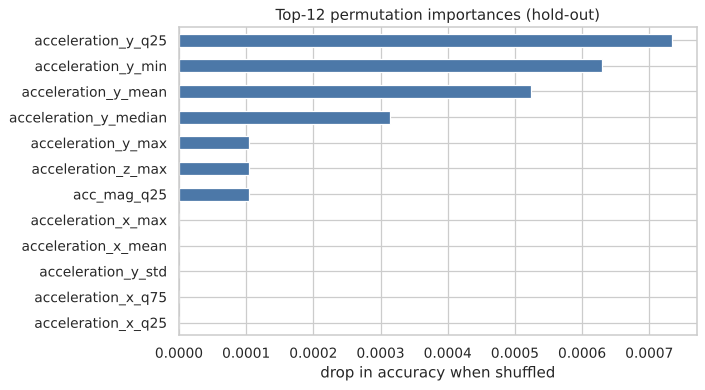

,importance
acceleration_y_q25,0.0007
acceleration_y_min,0.0006
acceleration_y_mean,0.0005
acceleration_y_median,0.0003
acceleration_y_max,0.0001
acceleration_z_max,0.0001
acc_mag_q25,0.0001
acceleration_x_max,0.0000
acceleration_x_mean,0.0000
acceleration_y_std,0.0000


In [32]:
# What drives the decision? Permutation importance on hold-out windows
pi = permutation_importance(final_model, Xw_test, yw_test, n_repeats=5, random_state=RANDOM_STATE, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=WIN_FEATS).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
imp[::-1].plot(kind="barh", color="#4C78A8", ax=ax); ax.set_title("Top-12 permutation importances (hold-out)")
ax.set_xlabel("drop in accuracy when shuffled")
plt.tight_layout(); plt.show()
imp.round(4).to_frame("importance")

### 3.5 Ablation: is the model recognising *motion*, or just *how the watch is oriented*?
Permutation importance shows the model leans on `acceleration_y` (gravity axis). That is partly **wrist orientation / arm posture**, which
could differ between walking and running recordings for reasons unrelated to motion intensity. We re-train with feature groups removed
to see how much of the accuracy survives. Scores: grouped CV on training days / hold-out days.

In [33]:
from sklearn.model_selection import cross_val_score
groups_ = {
    "All window features":                           WIN_FEATS,
    "Without wrist flag":                            [f for f in WIN_FEATS if f != "wrist"],
    "Without raw accelerometer (gyro + magnitudes)": [f for f in WIN_FEATS if not f.startswith("acceleration_")],
    "Gyroscope only (orientation-free spin)":        [f for f in WIN_FEATS if f.startswith("gyro_") and not f.startswith("gyro_mag")],
    "Spread only (std of every channel)":            [f for f in WIN_FEATS if f.endswith("_std")],
}
abl_models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
              "Hist. Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE)}
rows = []
for gname, feats in groups_.items():
    for mname, est in abl_models.items():
        cvs = cross_val_score(clone(est), Xw[feats], yw, cv=cv_groups, scoring="accuracy")
        te = accuracy_score(yw_test, clone(est).fit(Xw[feats], yw).predict(Xw_test[feats]))
        rows.append({"features": gname, "n_feats": len(feats), "model": mname, "cv_acc": cvs.mean(), "cv_min_fold": cvs.min(), "holdout_acc": te})
pd.DataFrame(rows).round(4).set_index(["features", "model"])

n_feats  cv_acc  cv_min_fold  holdout_acc
features                                      model                                                             
All window features                           Logistic Regression           57  0.9994       0.9972       1.0000
                                              Hist. Gradient Boosting       57  0.9990       0.9972       1.0000
Without wrist flag                            Logistic Regression           56  0.9994       0.9972       1.0000
                                              Hist. Gradient Boosting       56  0.9990       0.9972       1.0000
Without raw accelerometer (gyro + magnitudes) Logistic Regression           36  0.9446       0.7801       0.9864
                                              Hist. Gradient Boosting       36  0.9454       0.7625       0.9916
Gyroscope only (orientation-free spin)        Logistic Regression           21  0.8349       0.5065       0.5959
                                              Hist. Gradient Boosting       21  0.8673       0.5510       0.8003
Spread only (std of every channel)            Logistic Regression            8  0.9944       0.9731       0.9990
                                              Hist. Gradient Boosting        8  0.9912       0.9592       0.9984

## 3.7 Model comparison report — conclusions

**Evaluation protocol:** 10 training days with grouped 5-fold CV (whole days held out per fold), then a one-time check on 2 locked-away days (1,908 windows).

| Rank | Model (5-s window features) | Grouped CV accuracy | Remarks |
|---|---|---|---|
| 1 | Decision Tree | 1.0000 | Perfect but a single tree is unstable and over-fits easily; kept out of contention |
| 2 | RBF-SVM | 0.9998 | Excellent; heavier to deploy, no native probabilities |
| 3 | AdaBoost | 0.9996 | Excellent |
| 4 | **Logistic Regression** | 0.9994 → **1.0000 tuned** | Simple, fast, probabilistic, interpretable |
| 5 | Hist. Gradient Boosting | 0.9990 → 0.9996 tuned | Excellent |
| 6 | Random Forest | 0.9985 → 0.9996 tuned | Excellent, larger model |
| 7 | Extra Trees | 0.9962 | |
| 8 | KNN | 0.9412 | Distance-based, sensitive to fold shift |
| 9 | MLP | 0.9282 | Unstable across folds |
| 10 | Gaussian NB | 0.8735 | Independence assumption violated by correlated features |
| – | Dummy | 0.3116 | Baseline |

**Key conclusions**

1. **Feature engineering mattered far more than the algorithm.** Moving from single readings to 5-second windows lifted the best
   model from ~95% to ~99.9–100% and made nearly every algorithm family succeed. On the hold-out days a Random Forest on single readings scored 97.75%, while every tuned window model scored 100%.
2. **Validation design mattered more than the score.** A random split reported 99.2% for a model that is really ~89% on unseen days (single readings).
3. **Several models are statistically tied at the top.** Differences of 0.0002–0.001 amount to a handful of windows, so the choice should rest on *production* criteria
   (simplicity, speed, stability, calibrated probabilities, explainability), not on the last decimal.
4. **Hold-out check:** Logistic Regression, tuned Random Forest and tuned Gradient Boosting all classify all 1,908 hold-out windows correctly, in both wrists and both days.
   The hold-out is only two days / 6 sessions, so "100%" should be read as "no errors observed in a small sample", not as a guarantee.
5. **Ablation (3.5):** Keeping *only* the per-channel standard deviations (8 orientation-free "how violently is the arm moving" features) still gives 99.4% CV / 99.9% hold-out. So
   the model is genuinely detecting motion intensity and not merely the way the watch was strapped on. Removing the raw accelerometer features drops CV to ~94.5%, and gyroscope-only features are
   weak (83–87% CV, 60–80% hold-out), so the accelerometer is the essential sensor.

### ✅ Recommendation for production: **Logistic Regression on 5-second window features** (scaler + LR, C = 100)

* Best grouped-CV accuracy after tuning (1.0000, min fold 0.997) and 100% on hold-out days, for both wrists.
* ~3 ms per window including feature extraction; tiny model file; trivially portable to a phone/watch or microcontroller.
* Outputs a probability, so a confidence threshold or temporal smoothing can be applied.
* Coefficients are inspectable; no black box.
* **Fallback / challenger:** Hist. Gradient Boosting or Random Forest (same hold-out score) if non-linear behaviour appears with new users.

### ⚠️ Limits to state before deploying
* **One person only.** Gait, arm swing and watch position differ between people; generalisation to new users is untested. Collect multi-user data and validate with leave-one-person-out before a real release.
* Only two activities. Standing, cycling, stairs, etc. will be forced into "walking" or "running". Add an "other/idle" class or reject low-confidence predictions.
* Needs 25 consecutive readings (≈5 s) at 5 Hz, so the first prediction is available after 5 s.
* Monitor input drift (e.g. mean `acceleration_y`, window std) and re-train when it shifts.

### 3.6 Save the production model

In [34]:
import joblib
ARTIFACT = {"model": final_model, "features": WIN_FEATS, "channels": CHANNELS, "window": WINDOW,
            "stats": STATS, "labels": {0: "walking", 1: "running"}}
joblib.dump(ARTIFACT, "walk_run_model.joblib")

def predict_activity(window_df, artifact=ARTIFACT):
    """window_df: DataFrame with 25 consecutive readings (acceleration_x/y/z, gyro_x/y/z) and a 'wrist' column."""
    d = window_df.copy()
    d["acc_mag"] = np.sqrt((d[SENSORS[:3]] ** 2).sum(axis=1)); d["gyro_mag"] = np.sqrt((d[SENSORS[3:]] ** 2).sum(axis=1))
    f = window_stats(sliding_window_view(d[artifact["channels"]].to_numpy(), artifact["window"], axis=0))
    f = pd.DataFrame(np.column_stack([f, [[d["wrist"].iloc[0]]]]), columns=artifact["features"])
    p = artifact["model"].predict_proba(f)[0, 1] if hasattr(artifact["model"], "predict_proba") else None
    return artifact["labels"][int(artifact["model"].predict(f)[0])], p

# demo on one running and one walking window from the hold-out days
for act in (0, 1):
    s = test_df[(test_df.activity == act)].iloc[500:500 + WINDOW]
    label, prob = predict_activity(s)
    print(f"true={ARTIFACT['labels'][act]} -> predicted={label}  P(running)={prob:.3f}")

true=walking -> predicted=walking  P(running)=0.000
true=running -> predicted=running  P(running)=1.000


# PART 4 — Report on Challenges Faced and Techniques Used

| # | Challenge | Evidence in this data | Technique used | Why this technique |
|---|---|---|---|---|
| 1 | **Malformed timestamp** | The `time` column is `H:MM:SS:ns`, hours and the nanosecond field have lost leading zeros (lengths vary 14–18 characters); `pd.to_timedelta` failed on it | Split on `:`, converted each part separately, left-padded nanoseconds to 9 digits | Required to get correct ordering and the true 5 Hz rate; naïve parsing would silently produce wrong fractions of a second |
| 2 | **File not in time order** | `is_monotonic_increasing` was `False` | Sorted by timestamp, then rebuilt sessions from (gap > 1 s) or (date/wrist/activity change) | Windows and temporal features are only valid on contiguous recordings |
| 3 | **Uninformative / metadata columns** | `username` constant; `date`/`time` identify *when*, not *what* | Dropped username; used date/time only to build sessions and as CV groups | Prevents the model from memorising recording days |
| 4 | **Data leakage through autocorrelation** | Random split gave 99.2% vs 88.6% with day-grouped CV (same model) | `GroupKFold` by date + a locked-away hold-out of whole days | A realistic estimate of performance on new recordings; otherwise near-duplicate neighbouring readings inflate scores |
| 5 | **Awkward group structure** | Some days contain only one activity (7/10, 7/11, 7/16); a CV fold had a single class; hold-out has 72% running vs 44% in training | Reported macro-F1 and pooled ROC-AUC next to accuracy, examined fold composition, kept hold-out days that contain both classes | Per-fold accuracy alone is misleading when a fold has one class; also shows robustness to a shifted class mix |
| 6 | **Single readings are weak evidence** | Best single-reading model ≈ 95% CV | Aggregated 25 readings (5 s, stride 10) into mean/std/min/max/median/quartiles per channel + magnitudes | Walking vs running differs in amplitude/variability of a periodic motion, not in an instantaneous value |
| 7 | **Very uneven session lengths** | 54-row chunks vs a 5,681-row recording | Windows are built *inside* sessions only, never across breaks | Avoids windows mixing two activities or spanning a gap |
| 8 | **Skew & heavy tails / "outliers"** | `acceleration_z` skew −1.8; 9% IQR outliers for running `acceleration_x` | Kept outliers (they are real foot strikes); used `StandardScaler` for scale-sensitive models, tree models for scale-free comparison, robust window statistics (median, quartiles) | Removing them would delete the very signal that identifies running |
| 9 | **Orientation / sensor-placement confound** | Model leans on `acceleration_y`, which is partly gravity/posture; wrist flips the sign of axes | Added orientation-free magnitude features, kept the `wrist` flag, ran feature-group ablation | Verified the model works from motion intensity (std-only features reach 99.4% CV) rather than watch angle |
| 10 | **Compute limits** | 88k rows, single CPU; exact RBF-SVM is O(n²–n³) | Row-level SVM trained on a 12k subsample per fold; windowing reduced data to ~6k rows | Keeps the comparison fair and runnable in minutes |
| 11 | **Model selection with near-tied scores** | Six models within 0.001 of each other | Tuned the strongest candidates with randomised search under the same grouped CV, then chose on production criteria (simplicity, latency, probabilities, explainability) | Avoids picking a winner on noise |
| 12 | **Single-user data** | Only `viktor` | Stated explicitly as a limitation, recommended leave-one-person-out validation with more users | Honest scope of the claim; this cannot be fixed with a modelling trick |

---
# Final Summary

* **Task 1 (analysis):** clean, balanced 5 Hz single-user dataset; running is distinguished mainly by a different gravity-axis level (`acceleration_y`) and much larger movement variability; recordings are structured in 339 sessions over 12 days.
* **Task 2 (model):** a classifier on 5-second window statistics, validated by holding out whole days.
* **Task 3 (comparison):** 11 algorithms × 2 feature views; windows reach ~99.9–100%, single readings ≤ ~95%. **Recommended: Logistic Regression on window features** (100% on hold-out days, ~3 ms per window); model saved to `walk_run_model.joblib` with a `predict_activity()` helper.
* **Task 4 (challenges):** timestamp repair, leakage-safe validation, windowing, outlier handling, orientation ablation and the single-user limitation are documented above.

**Before relying on it for real users:** validate on additional people and activities.